[![Abrir no Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lalvim/DataMining/blob/main/notebooks/unidade_07/07_01_caracterizacao_de_outliers.ipynb)

# Unidade VII — Detecção de *Outliers*

## Caracterização de *outliers*

**Carga estimada:** 1 hora e 30 minutos  
**Pré-requisitos:** tipos de dados, estatística descritiva e visualização.

> **Pergunta norteadora:** o que significa dizer que uma observação é anômala e por que essa conclusão depende dos atributos, do contexto e da unidade analisada?

Um *outlier* é uma observação, sequência ou conjunto que se afasta de um padrão de referência relevante. A palavra descreve uma relação com os dados; não identifica automaticamente erro, fraude, falha ou qualquer outra causa.

## Objetivos de aprendizagem

Ao concluir este notebook, você será capaz de:

- caracterizar *outliers* como desvios relativos a uma referência;
- distinguir observação anômala de sua possível causa;
- diferenciar anomalias globais, contextuais e coletivas;
- distinguir caracterizações univariadas e multivariadas;
- explicar como a forma da anomalia muda com atributos, escala e contexto;
- reconhecer aplicações e consequências de decisões baseadas em alertas.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (9, 5), "figure.dpi": 120})

## 1. Anomalia em relação a quê?

Caracterizar um *outlier* exige explicitar pelo menos cinco escolhas:

1. **unidade de análise:** uma medição, transação, pessoa, máquina, janela temporal ou trajetória;
2. **população de referência:** todos os registros ou apenas os comparáveis;
3. **atributos:** quais dimensões definem semelhança e desvio;
4. **contexto:** horário, estação, operação, localização ou perfil;
5. **escala temporal:** instante, dia, mês ou sequência completa.

O mesmo valor pode ser típico em uma população e raro em outra. Portanto, “ser anômalo” não é uma propriedade permanente do objeto.

## 2. Anomalias globais, contextuais e coletivas

| Tipo | O que se afasta do padrão? | Exemplo |
|---|---|---|
| global | uma observação em relação ao conjunto inteiro | temperatura muito acima de toda a faixa operacional |
| contextual | uma observação condicionada a circunstância específica | consumo comum à tarde, mas incomum de madrugada |
| coletiva | uma sequência ou conjunto cuja organização é incomum | oscilações individualmente plausíveis que formam padrão repetitivo de falha |

As categorias podem se sobrepor. Um ponto pode ser globalmente extremo e também contextual; uma sequência coletiva pode conter alguns pontos globalmente comuns.

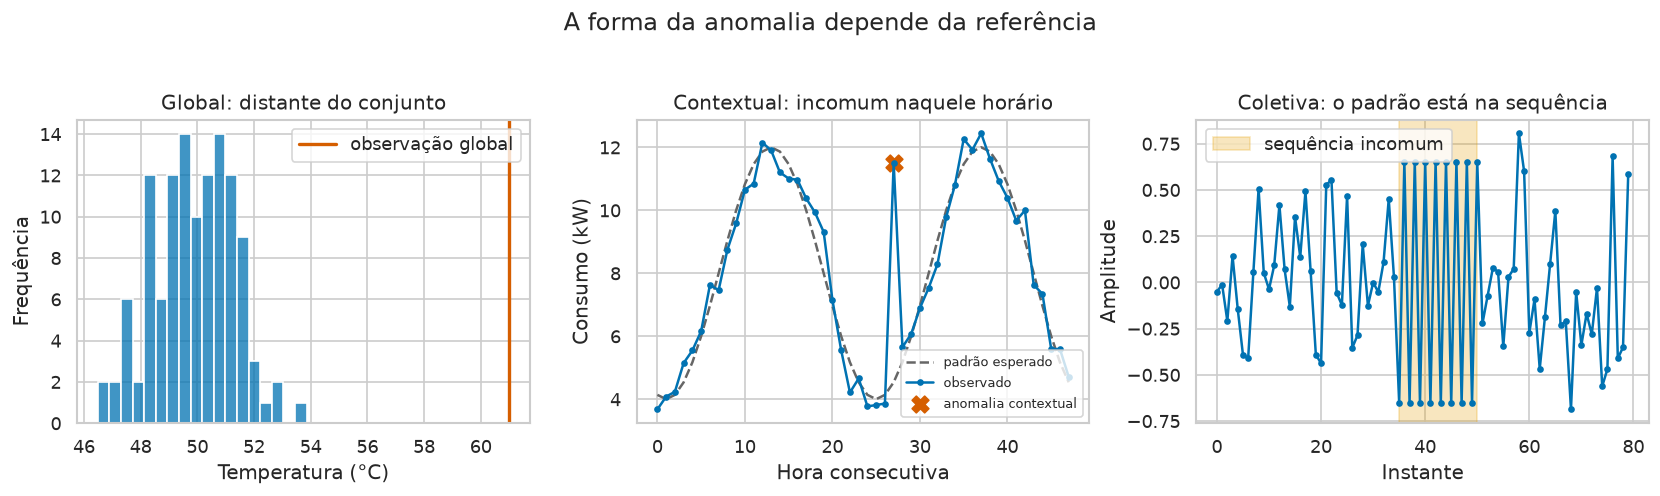

In [2]:
rng = np.random.default_rng(RANDOM_STATE)

# Global: um valor distante de toda a distribuição.
temperaturas = rng.normal(50, 1.8, 120)
temperatura_global = 61

# Contextual: valor plausível no dia, mas incomum de madrugada.
horas = np.arange(48)
hora_do_dia = horas % 24
consumo_esperado = 8 + 4 * np.sin((hora_do_dia - 7) * np.pi / 12)
consumo = consumo_esperado + rng.normal(0, 0.45, len(horas))
indice_contextual = 27  # 3 horas da madrugada do segundo dia
consumo[indice_contextual] = 11.5

# Coletiva: valores moderados, mas uma alternância organizada e incomum.
sinal = rng.normal(0, 0.32, 80)
janela_coletiva = np.arange(35, 51)
sinal[janela_coletiva] = np.tile([-0.65, 0.65], 8)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(temperaturas, bins=18, color="#0072B2", ax=axes[0])
axes[0].axvline(temperatura_global, color="#D55E00", linewidth=2, label="observação global")
axes[0].set(title="Global: distante do conjunto", xlabel="Temperatura (°C)", ylabel="Frequência")
axes[0].legend()

axes[1].plot(horas, consumo_esperado, linestyle="--", color="#666666", label="padrão esperado")
axes[1].plot(horas, consumo, marker="o", markersize=3, color="#0072B2", label="observado")
axes[1].scatter(horas[indice_contextual], consumo[indice_contextual], color="#D55E00", marker="X", s=100, label="anomalia contextual")
axes[1].set(title="Contextual: incomum naquele horário", xlabel="Hora consecutiva", ylabel="Consumo (kW)")
axes[1].legend(fontsize=8)

axes[2].plot(sinal, marker="o", markersize=3, color="#0072B2")
axes[2].axvspan(janela_coletiva[0], janela_coletiva[-1], color="#E69F00", alpha=0.25, label="sequência incomum")
axes[2].set(title="Coletiva: o padrão está na sequência", xlabel="Instante", ylabel="Amplitude")
axes[2].legend()
fig.suptitle("A forma da anomalia depende da referência", y=1.03)
fig.tight_layout()
plt.show()

## 3. Dados univariados e multivariados

Na caracterização **univariada**, cada variável é examinada separadamente. Um valor pode se destacar por estar muito distante do centro ou em uma cauda pouco frequente.

Na caracterização **multivariada**, importa a combinação dos atributos. Uma observação pode ter valores comuns em cada variável isolada e, ainda assim, apresentar combinação rara. Por exemplo, peso e altura podem estar dentro das faixas usuais separadamente, mas sua relação pode destoar da população de referência.

A dimensionalidade não determina a causa. Ela apenas muda a representação na qual o desvio é observado.

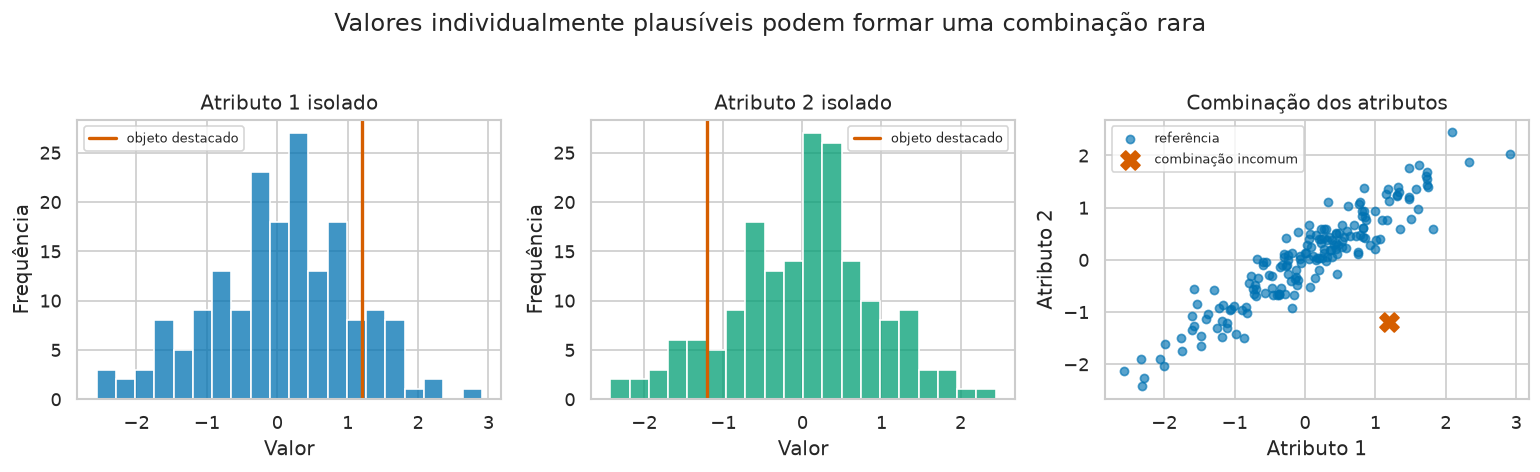

In [3]:
x = rng.normal(0, 1, 180)
y = 0.85 * x + rng.normal(0, 0.32, len(x))
ponto_multivariado = np.array([1.2, -1.2])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
sns.histplot(x, bins=20, color="#0072B2", ax=axes[0])
axes[0].axvline(ponto_multivariado[0], color="#D55E00", linewidth=2, label="objeto destacado")
axes[0].set(title="Atributo 1 isolado", xlabel="Valor", ylabel="Frequência")
axes[0].legend(fontsize=8)

sns.histplot(y, bins=20, color="#009E73", ax=axes[1])
axes[1].axvline(ponto_multivariado[1], color="#D55E00", linewidth=2, label="objeto destacado")
axes[1].set(title="Atributo 2 isolado", xlabel="Valor", ylabel="Frequência")
axes[1].legend(fontsize=8)

axes[2].scatter(x, y, s=24, alpha=0.65, color="#0072B2", label="referência")
axes[2].scatter(*ponto_multivariado, marker="X", s=130, color="#D55E00", label="combinação incomum")
axes[2].set(title="Combinação dos atributos", xlabel="Atributo 1", ylabel="Atributo 2")
axes[2].legend(fontsize=8)
fig.suptitle("Valores individualmente plausíveis podem formar uma combinação rara", y=1.03)
fig.tight_layout()
plt.show()

## 4. A forma pode mudar

Em uma dimensão, uma anomalia costuma aparecer nas extremidades ou em uma região pouco ocupada da distribuição. Em várias dimensões, ela pode assumir outras formas:

- ponto isolado da nuvem principal;
- combinação que viola uma relação entre atributos;
- observação rara apenas dentro de uma vizinhança local;
- pequeno grupo separado, que pode representar subpopulação legítima;
- trajetória ou sequência com ordem incomum.

Adicionar atributos, mudar unidades ou padronizar os dados altera distâncias e vizinhanças. Uma projeção em duas dimensões também pode aproximar pontos originalmente distantes ou esconder separações.

## 5. Observação, causa e ação são coisas diferentes

| Possível origem | Exemplo | Verificação necessária |
|---|---|---|
| erro de medição ou digitação | unidade incorreta, sensor descalibrado | fonte original, calibração e regras de validade |
| integração ou processamento | duplicidade, coluna deslocada, conversão errada | linhagem e etapas do pipeline |
| evento raro legítimo | pico real de demanda ou caso clínico incomum | contexto operacional e fonte independente |
| mudança de processo | novo equipamento, política ou população | comparação temporal e documentação da mudança |
| ação adversarial | fraude ou intrusão | evidências adicionais e investigação autorizada |

Um detector não observa diretamente essas causas. Ele produz um alerta sobre o padrão registrado. Diagnosticar a origem e decidir uma ação são etapas posteriores.

## 6. Exemplos de aplicação

| Área | Unidade analisada | Possível anomalia | Cuidado de interpretação |
|---|---|---|---|
| qualidade de dados | registro | idade impossível ou categoria desconhecida | corrigir somente com evidência da fonte |
| indústria | janela de sensores | combinação de calor, pressão e vibração | mudança operacional pode explicar o alerta |
| finanças | transação ou sequência | valor, local e horário incompatíveis com histórico | alerta não prova fraude |
| segurança digital | sessão ou fluxo de rede | sequência incomum de acessos | novidade legítima pode parecer ataque |
| saúde | paciente ou exame | combinação rara de medidas | população de referência e consequência clínica importam |
| meio ambiente | estação e período | leitura incompatível com sazonalidade local | falha de sensor e evento extremo exigem respostas distintas |

Em aplicações sobre pessoas, um alerta não deve gerar sanção automática. Devem existir revisão, rastreabilidade, proteção dos dados e possibilidade de contestação.

## 7. Antes de escolher um método

Uma formulação mínima deve responder:

1. qual evento ou risco motiva a investigação?
2. qual é a unidade de análise?
3. qual população e período formam a referência?
4. o desvio esperado é univariado, multivariado, contextual ou coletivo?
5. quais rótulos ou confirmações estão disponíveis?
6. quantos casos podem ser investigados?
7. quais são os custos de falso alerta e caso perdido?
8. quem revisa a decisão e como o dado original será preservado?

Os notebooks seguintes apresentam métodos univariados e multivariados para produzir evidências depois dessas escolhas.

## 8. Atividades

**U07-NB01-V01.** Um consumo de 12 kW é comum durante o expediente e incomum de madrugada. Explique por que o valor não é globalmente anômalo, mas pode ser contextual.

**U07-NB01-E01.** Para monitorar uma máquina, compare três unidades de análise: leitura instantânea, janela de cinco minutos e trajetória diária. Indique que tipo de anomalia cada unidade consegue representar melhor.

**U07-NB01-E02.** Crie um exemplo em que duas medidas sejam comuns quando analisadas separadamente, mas sua combinação seja rara. Explique por que a análise univariada não basta.

**U07-NB01-E03.** Escolha duas áreas da tabela de aplicações. Para cada uma, defina unidade, referência, atributos, possível causa e consequência de um falso alerta.

**U07-NB01-E04.** Um pequeno grupo de clientes aparece isolado em uma visualização bidimensional. Liste quatro explicações alternativas e três verificações necessárias antes de chamá-lo de anômalo.

## 9. Síntese

- *Outliers* são definidos em relação a unidade, população, atributos, contexto e período.
- Anomalias globais, contextuais e coletivas descrevem referências diferentes.
- Dados podem ser analisados de forma univariada ou multivariada; combinações raras podem ser invisíveis nas marginais.
- A forma observada muda com dimensionalidade, escala, vizinhança e projeção.
- Um alerta descreve desvio; causa, importância e ação exigem investigação adicional.

## Referências

- HAN, J.; PEI, J.; TONG, H. *Data Mining: Concepts and Techniques*. 4. ed. Morgan Kaufmann, 2023. Cap. 11.
- AGGARWAL, C. C. *Outlier Analysis*. 2. ed. Springer, 2017.
- CHANDOLA, V.; BANERJEE, A.; KUMAR, V. Anomaly detection: a survey. *ACM Computing Surveys*, v. 41, n. 3, 2009.

Os dados e as figuras deste notebook são sintéticos e autorais.